<a href="https://colab.research.google.com/github/mj-amin-ece/GATN/blob/main/GATN_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
import sys

In [ ]:
drive.mount('/content/gdrive')
sys.path.append('/content/gdrive/MyDrive/GATN')
os.chdir('/content/gdrive/MyDrive/GATN')

Mounted at /content/gdrive


#Imports

In [ ]:
!pip install torchnet

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for torchnet: filename=torchnet-0.0.4-py3-none-any.whl size=29727 sha256=8cda6c302c7418e62de99272cd7606eece17f5d20bc9363bdb0a014dbf5f2b10
  Stored in directory: /root/.cache/pip/wheels/69/12/36/73a61a7ea788c74f258d51c041265c2a5c06dec6ec04ca847b
  Created wheel for visdom: filename=visdom-0.2.4-py3-none-any.whl size=1408195 sha256=45ed9d073bf41f4f5436ab843bd4b7fcc7449094683036e78ecc8f75b717093c
  Stored in directory: /root/.cache/pip/wheels/37/6c/38/64eeaa310e325aacda723e6df1f79ab5e9f31ba195264e04a8
Successfully built torchnet visdom


In [ ]:
from torch.nn import CrossEntropyLoss, BCELoss, Dropout, Softmax, Sigmoid, Linear, Conv2d, LayerNorm
from torch.nn.modules.utils import _pair
from torch.nn import Parameter
import torchvision.models as models
import torch
import torch.nn as nn
import torchnet as tnt
import shutil
import time
import torch.backends.cudnn as cudnn
from torchvision import models as tv_models
from transformers import AutoTokenizer, AutoModel
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from openai import OpenAI
import pickle
from torchvision import models, transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import pickle

from scipy import ndimage
import numpy as np
import pandas as pd
import torch
import math
from PIL import Image, ImageOps

from os.path import join as pjoin

from typing import Dict, Tuple, Optional, List
import numpy as np
from dataclasses import dataclass


In [ ]:
client = OpenAI()

OpenAIError: The api_key client option must be set either by passing api_key to the client or by setting the OPENAI_API_KEY environment variable

# Attention

In [ ]:
class SelfAttention(nn.Module):
    def __init__(self, embed_size, heads):
        super().__init__()
        self.heads = heads
        self.embed_size = embed_size
        self.head_dim = embed_size // heads
        assert self.head_dim * heads == embed_size, "Embedding size must be divisible by heads"

        # Projections operate per head_dim (because we reshape first)
        self.q_proj = nn.Linear(self.head_dim, self.head_dim, bias=False)
        self.k_proj = nn.Linear(self.head_dim, self.head_dim, bias=False)
        self.v_proj = nn.Linear(self.head_dim, self.head_dim, bias=False)

        self.fc_out = nn.Linear(embed_size, embed_size)

    def forward(self, values, keys, query, mask=None):
        N = query.shape[0]
        value_len, key_len, query_len = values.shape[1], keys.shape[1], query.shape[1]

        # split embedding into heads
        values = values.reshape(N, value_len, self.heads, self.head_dim)
        keys   = keys.reshape(  N, key_len,  self.heads, self.head_dim)
        query  = query.reshape( N, query_len, self.heads, self.head_dim)

        # apply per-head projections
        q = self.q_proj(query)   # (N, query_len, H, Hd)
        k = self.k_proj(keys)    # (N, key_len,  H, Hd)
        v = self.v_proj(values)  # (N, value_len, H, Hd)

        # scaled dot-product attention
        energy = torch.einsum("nqhd,nkhd->nhqk", q, k)  # (N, H, Q, K)

        if mask is not None:
            # Expect mask broadcastable to (N, H, Q, K)
            energy = energy.masked_fill(mask == 0, float("-1e20"))

        attn = torch.softmax(energy / (self.head_dim ** 0.5), dim=-1)

        out = torch.einsum("nhqk,nkhd->nqhd", attn, v)  # (N, Q, H, Hd)
        out = out.reshape(N, query_len, self.heads * self.head_dim)  # (N, Q, D)
        out = self.fc_out(out)
        return out


In [ ]:
class AttentionBlock(nn.Module):
    def __init__(self, embed_size, heads):
        super().__init__()
        self.embed_size = embed_size
        self.norm = nn.LayerNorm(embed_size, eps=1e-6)

        self.attn1 = SelfAttention(embed_size, heads)
        self.attn2 = SelfAttention(embed_size, heads)
        self.attn3 = SelfAttention(embed_size, heads)
        self.attn4 = SelfAttention(embed_size, heads)

    def forward(self, x, y=None, mask=None, y_mask=None):
        B, L, D = x.shape
        if D != self.embed_size:
            raise ValueError(f"x hidden size {D} != embed_size {self.embed_size}")
        if y is not None:
            if y.shape[0] != B:
                raise ValueError("x and y must have the same batch size")
            if y.shape[1] != L or y.shape[2] != D:
                raise ValueError("For this fusion, x and y must have the same (seq_len, hidden_size)")

        # branch 1
        x1 = self.attn1(self.norm(x), self.norm(x), self.norm(x), mask)
        if y is not None:
            y1 = self.attn3(self.norm(y), self.norm(y), self.norm(y), y_mask)
            x1 = x1 + y1

        # branch 2
        x2 = self.attn2(self.norm(x), self.norm(x), self.norm(x), mask)
        if y is not None:
            y2 = self.attn4(self.norm(y), self.norm(y), self.norm(y), y_mask)
            x2 = x2 + y2

        # pairwise token affinity (B, L, L)
        x_out = torch.bmm(x1, x2.transpose(1, 2))
        return x_out

#GNC

In [ ]:
class GraphConvolution(nn.Module):
  def __init__(self, in_features, out_features, bias=False):
    super(GraphConvolution, self).__init__()
    self.in_features = in_features
    self.out_features = out_features
    self.weight = nn.Parameter(torch.FloatTensor(in_features, out_features))
    if bias:
      self.bias = nn.Parameter(torch.FloatTensor(1, 1, out_features))
    else:
      self.register_parameter('bias', None)
    self.reset_parameters()

  def reset_parameters(self):
    stdv = 1. / math.sqrt(self.weight.size(1))
    self.weight.data.uniform_(-stdv, stdv)
    if self.bias is not None:
      self.bias.data.uniform_(-stdv, stdv)

  def forward(self, input, adj):
    support = torch.matmul(input, self.weight)
    output = torch.matmul(adj, support)
    if self.bias is not None:
      return output + self.bias
    else:
      return output
  def __repr__(self):
    return self.__class__.__name__ + ' (' \
           + str(self.in_features) + ' -> ' \
           + str(self.out_features) + ')'

# GATN

In [ ]:
class GATN(nn.Module):
    def __init__(self, model_name, num_classes, embedding_size, t1, t2,
                 adj_file, matrix_mode, A_number):
        super().__init__()
        if A_number not in (1, 2):
            raise ValueError(f"A_number must be 1 or 2, got {A_number}")
        self.model_name = model_name
        self.num_classes = num_classes
        self.embedding_size = embedding_size
        self.t1 = t1
        self.t2 = t2
        self.adj_file = adj_file
        self.A_number = A_number
        self.matrix_mode = matrix_mode

        # --- Backbone: returns (B, feat_dim) because pool="avg" ---
        self.backbone, self.feat_dim = load_backbone(
            self.model_name, pretrained=True, pool="avg", freeze=False
        )

        # Project visual features to match GCN output (1024)
        self.feat_proj = nn.Linear(self.feat_dim, 1024)

        # --- Graph branch ---
        self.gc1 = GraphConvolution(self.embedding_size, 512)
        self.gc2 = GraphConvolution(512, 1024)
        self.relu = nn.ReLU()

        # --- Attention over adjacency ---
        self.transformerblock = AttentionBlock(num_classes, 2)

        # Final linear over class dimension
        self.linear_A = nn.Linear(self.num_classes, self.num_classes)

        # --- Base adjacencies -> buffers (move with .to(device)) ---
        if self.matrix_mode == "correlation":
            s_adj = gen_A_correlation(num_classes, t1, t2, adj_file)  # (N, N) numpy
            if self.A_number == 2:
                s_adj1 = gen_A_correlation(num_classes, t2, t1, adj_file)
        elif self.matrix_mode == "co-occurrence":
            s_adj = gen_A(num_classes, t1, t2, adj_file)              # (N, N) numpy
            if self.A_number == 2:
                s_adj1 = gen_A(num_classes, t2, t1, adj_file)
        else:
            raise ValueError(f"Unknown matrix mode: {self.matrix_mode}")

        # Register base adjacencies as buffers
        A1 = torch.from_numpy(s_adj).float().unsqueeze(0)             # (1, N, N)
        self.register_buffer("A_1", A1)
        if self.A_number == 2:
            A2 = torch.from_numpy(s_adj1).float().unsqueeze(0)        # (1, N, N)
            self.register_buffer("A_2", A2)
        else:
            # Not registered; keeps named_buffers clean
            self.A_2 = None

        # Optional shape sanity checks (helpful during integration)
        if self.A_1.shape != (1, num_classes, num_classes):
            raise ValueError(f"A_1 shape {tuple(self.A_1.shape)} != (1, {num_classes}, {num_classes})")
        if self.A_number == 2 and self.A_2.shape != (1, num_classes, num_classes):
            raise ValueError(f"A_2 shape {tuple(self.A_2.shape)} != (1, {num_classes}, {num_classes})")

    def forward(self, image: torch.Tensor, embedding: torch.Tensor) -> torch.Tensor:
        """
        image:     (B, 3, H, W)  -> backbone outputs (B, feat_dim) because pool='avg'
        embedding: (num_classes, embedding_size) class embeddings
        """
        # --- Visual features ---
        feat = self.backbone(image)          # (B, feat_dim)
        feat = self.feat_proj(feat)          # (B, 1024)

        # --- Adaptive adjacency via transformer ---
        if self.A_number == 2:
            adj_raw_out = self.transformerblock(self.A_1, self.A_2)   # expect Tensor or (Tensor, ...)
        else:
            adj_raw_out = self.transformerblock(self.A_1)

        # Accept either Tensor or tuple/list with the first item being the Tensor
        adj_raw = adj_raw_out[0] if isinstance(adj_raw_out, (tuple, list)) else adj_raw_out  # (1, N, N) or (N, N)
        if adj_raw.dim() == 3 and adj_raw.size(0) == 1:
            adj_raw = adj_raw.squeeze(0)     # (N, N)
        elif adj_raw.dim() != 2:
            raise ValueError(f"transformerblock must return (1,N,N) or (N,N); got {tuple(adj_raw.shape)}")

        # Add self-loops and normalize
        I = torch.eye(self.num_classes, dtype=adj_raw.dtype, device=adj_raw.device)
        adj = gen_adj(adj_raw + I)           # (N, N) normalized adjacency

        # --- Ensure embedding shape is (N, D) and move to correct device/dtype ---
        if embedding.dim() == 3 and embedding.size(0) == 1:
            embedding = embedding.squeeze(0)
        if embedding.shape != (self.num_classes, self.embedding_size):
            raise ValueError(
                f"Expected embedding {(self.num_classes, self.embedding_size)}, got {tuple(embedding.shape)}"
            )
        embedding = embedding.to(dtype=feat.dtype, device=feat.device)

        # --- Graph convolutions on class embeddings ---
        x = self.gc1(embedding, adj)         # (N, 512)
        x = self.relu(x)
        x = self.gc2(x, adj)                 # (N, 1024)
        x = x.t()                            # (1024, N)

        # --- Fuse visual features with class prototypes ---
        out = torch.matmul(feat, x)          # (B, N)
        out = self.linear_A(out)             # (B, N)
        return out

    def get_config_optim(self, lr, lrp, lrt):
        return [
            {'params': self.backbone.parameters(),         'lr': lr * lrp},
            {'params': self.transformerblock.parameters(), 'lr': lr * lrt},
            {'params': self.gc1.parameters(),              'lr': lr},
            {'params': self.gc2.parameters(),              'lr': lr},
            {'params': self.feat_proj.parameters(),        'lr': lr},
            {'params': self.linear_A.parameters(),         'lr': lr},
        ]


# Utils

In [ ]:
# ---------- optional: GeM pooling (often nice for retinal images) ----------
class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps
    def forward(self, x):
        x = x.clamp(min=self.eps).pow(self.p)
        x = torch.mean(x, dim=(-2, -1), keepdim=True)
        return x.pow(1.0 / self.p)

try:
    import timm
    _has_timm = True
except ImportError:
    _has_timm = False


def load_backbone(model_name: str,
                  pretrained: bool = True,
                  pool: str = "avg",           # "avg" | "max" | "gem" | "" (no pool, return feature maps if supported)
                  token_pool: str = "cls",      # for ViTs when pool=="": "cls" or "mean"
                  freeze: bool = False,
                  return_dim: bool = True):
    """
    Returns (model, feat_dim) where model.forward(x)->(B, feat_dim) if pooled,
    otherwise feature maps / tokens depending on backbone.

    For multi-label heads later, you’ll attach your own nn.Linear(feat_dim, num_classes).
    """
    name = (model_name or "").lower()

    # -------------------------- timm (recommended) --------------------------
    if _has_timm:
        # If you want feature vectors directly, set num_classes=0 so timm applies its global_pool.
        if pool in {"avg", "max", "avgmax", "cat"}:
            m = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool=pool)
            feat_dim = getattr(m, "num_features", None)
            if freeze:
                for p in m.parameters(): p.requires_grad = False
            return (m, feat_dim) if return_dim else m

        # If you want raw feature maps/tokens (no pooling), use global_pool=""
        if pool in {"", None}:
            m = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool="")
            feat_dim = getattr(m, "num_features", None)  # token/feature size (not spatial)
            # Wrap forward to turn maps/tokens into vectors if you still want token pooling
            def forward_no_pool(x):
                feats = m.forward_features(x)
                # CNNs: (B, C, H, W). ViTs: (B, N, C) or (B, C)
                if feats.dim() == 4:  # CNN maps
                    return feats  # (B, C, H, W)
                if feats.dim() == 3:  # tokens
                    if token_pool == "mean":
                        return feats.mean(dim=1)           # (B, C)
                    return feats[:, 0]                     # CLS token (B, C)
                return feats  # already (B, C)
            m.forward = forward_no_pool
            if freeze:
                for p in m.parameters(): p.requires_grad = False
            return (m, feat_dim) if return_dim else m

        # Custom GeM pooling on top of forward_features (outputs a vector)
        if pool == "gem":
            base = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool="")
            feat_dim = getattr(base, "num_features", None)
            gem = GeM()

            class TimmGeM(nn.Module):
                def __init__(self, backbone, gem_pool):
                    super().__init__()
                    self.backbone = backbone
                    self.pool = gem_pool
                    self.feat_dim = getattr(backbone, "num_features", None)
                def forward(self, x):
                    f = self.backbone.forward_features(x)
                    if f.dim() == 4:  # CNNs
                        f = self.pool(f).flatten(1)
                    elif f.dim() == 3:  # ViTs tokens
                        # apply mean over tokens before GeM (robust), then identity GeM (acts as pow-mean on 1x1)
                        f = f.mean(1)  # (B, C)
                    return f
            m = TimmGeM(base, gem)
            if freeze:
                for p in m.parameters(): p.requires_grad = False
            return (m, feat_dim) if return_dim else m

    # -------------------------- torchvision fallbacks --------------------------
    # ResNet
    if name in {"resnet18","resnet34","resnet50","resnet101","resnet152"}:
        wmap = {
            "resnet18": tv_models.ResNet18_Weights,
            "resnet34": tv_models.ResNet34_Weights,
            "resnet50": tv_models.ResNet50_Weights,
            "resnet101": tv_models.ResNet101_Weights,
            "resnet152": tv_models.ResNet152_Weights,
        }
        weights = getattr(wmap[name], "IMAGENET1K_V1") if pretrained else None
        m = getattr(tv_models, name)(weights=weights)
        feat_dim = m.fc.in_features
        m.fc = nn.Identity()  # now forward returns pooled features
        if pool == "gem":
            m.avgpool = GeM()
        if freeze:
            for p in m.parameters(): p.requires_grad = False
        return (m, feat_dim) if return_dim else m

    # DenseNet
    if name == "densenet121":
        weights = tv_models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        m = tv_models.densenet121(weights=weights)
        feat_dim = m.classifier.in_features
        m.classifier = nn.Identity()  # forward returns pooled features
        if freeze:
            for p in m.parameters(): p.requires_grad = False
        return (m, feat_dim) if return_dim else m

    # Inception v3 (expects 299x299)
    if name == "inception_v3":
        weights = tv_models.Inception_V3_Weights.IMAGENET1K_V1 if pretrained else None
        m = tv_models.inception_v3(weights=weights, aux_logits=False)
        feat_dim = m.fc.in_features
        m.fc = nn.Identity()
        if freeze:
            for p in m.parameters(): p.requires_grad = False
        return (m, feat_dim) if return_dim else m

    raise ValueError(f"Unknown backbone: {model_name}")


# # ------------------------------ helper: transforms ------------------------------
# def get_backbone_transforms(model_name: str):
#     """
#     Returns (size, mean, std) to match pretrained normalization.
#     """
#     name = (model_name or "").lower()
#     if _has_timm:
#         cfg = timm.data.resolve_model_data_config(timm.create_model(name, pretrained=True))
#         size = cfg.get("input_size", (3, 224, 224))[-1]
#         mean = cfg.get("mean", (0.485, 0.456, 0.406))
#         std  = cfg.get("std",  (0.229, 0.224, 0.225))
#         return size, mean, std
#     # torchvision defaults
#     if "inception" in name:
#         return 299, (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)
#     return 224, (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


# Embedding

In [ ]:
RETINAX_LABEL_EXPANSIONS: dict[str, str] = {
    "DR": "Diabetic Retinopathy",
    "NORMAL": "Normal retina",
    "MH": "Media Haze",
    "ODC": "Optic Disc Cupping",
    "TSLN": "Retinal Tessellation",
    "ARMD": "Age-Related Macular Degeneration",
    "DN": "Drusen",
    "MYA": "Myopia",
    "BRVO": "Branch Retinal Vein Occlusion",
    "ODP": "Optic Disc Pallor",
    "CRVO": "Central Retinal Vein Occlusion",
    "CNV": "Choroidal Neovascularization",
    "RS": "Retinitis",
    "ODE": "Optic Disc Edema",
    "LS": "Laser Scars",
    "CSR": "Central Serous Retinopathy",
    "HTR": "Hypertensive Retinopathy",
    "ASR": "Arteriosclerotic Retinopathy",
    "CRS": "Chorioretinitis",
    "OTHER": "OTHER",
}

data = pd.read_csv("/content/gdrive/MyDrive/GATN/dataset/train_data.csv")
data.drop(columns=["ID"],inplace=True)
labels = data.columns.to_list()
text_labels = [RETINAX_LABEL_EXPANSIONS[label] for label in labels]

## Helper Functions

In [ ]:
def bert_embedding(labels,embed_name, model_name, tokenizer_name, max_length=25, cache_dir="embeddings"):
    """
    Compute (and cache) CLS embeddings for a list of labels using a HuggingFace model.
    No batching, processes each label individually.

    Args:
        labels (List[str]): List of label strings to embed.
        dim (int): Only used in the cache filename (actual model dimension is fixed).
        model_name (str): HuggingFace model id.
        tokenizer_name (str): HuggingFace tokenizer id.
        max_length (int): Max sequence length.
        cache_dir (str): Directory to store embeddings.

    Returns:
        np.ndarray of shape (len(labels), hidden_size)
    """
    os.makedirs(cache_dir, exist_ok=True)
    filename = f"bert_embedding_{embed_name}.pkl"
    cache_path = os.path.join(cache_dir, filename)

    # If cached, load and return
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            return pickle.load(f)

    # Load tokenizer/model
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_name)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = AutoModel.from_pretrained(
        model_name,
        token="***REDACTED_HF_TOKEN***"
    ).to(device).eval()

    embs = []
    with torch.no_grad():
        for label in labels:
            toks = tokenizer.encode_plus(
                label,
                padding="max_length",
                max_length=max_length,
                truncation=True,
                return_tensors="pt"
            )
            toks = {k: v.to(device) for k, v in toks.items()}
            outputs = model(**toks)
            cls_rep = outputs.last_hidden_state[:, 0, :]  # CLS
            embs.append(cls_rep.cpu().numpy())

    embs = np.vstack(embs)

    # Save to cache
    with open(cache_path, "wb") as f:
        pickle.dump(embs, f)

    return embs

def openai_embedding(labels, dim):

    filename = f"openai_embedding_{dim}.pkl"

    if os.path.exists(f"embeddings/{filename}"):
        with open(f"embeddings/{filename}", "rb") as f:
            embeddings = pickle.load(f)
        return embeddings

    resp = client.embeddings.create(
        model="text-embedding-3-small",
        input=labels,
        dimensions=dim
    )
    resp = client.embeddings.create(
    model="text-embedding-3-large",
    input=labels,
    dimensions=512
    )

    # extract embeddings as numpy array
    embeddings = np.array([d.embedding for d in resp.data])

    # save as pickle
    with open(f"embeddings/{filename}", "wb") as f:
        pickle.dump(embeddings, f)

    print("Saved embeddings shape:", embeddings.shape)
    return embeddings

# ADJ Matrix

In [ ]:
def get_adj_matrices(csv_file="train_data.csv",
                     co_adj_file="Adj_matrix/co_adj.pkl",
                     corr_adj_file="Adj_matrix/corr_adj.pkl"):
    """
    Load or compute co-occurrence and correlation adjacency matrices.
    Returns them as numpy arrays.
    """

    if os.path.exists(co_adj_file) and os.path.exists(corr_adj_file):
        # Load from pickle
        with open(co_adj_file, "rb") as f:
            co_adj = pickle.load(f)
        with open(corr_adj_file, "rb") as f:
            corr_adj = pickle.load(f)
    else:
        # Read CSV and preprocess
        data = pd.read_csv(csv_file)
        data.drop(columns=["ID"], inplace=True)
        labels = data.columns.to_list()
        X = data.values  # shape (n_samples, n_labels)

        # Co-occurrence adjacency
        counts = X.T @ X
        co_adj = pd.DataFrame(counts, index=labels, columns=labels)

        # Correlation adjacency
        corr_adj = data.corr(method="pearson")

        # Save both
        with open(co_adj_file, "wb") as f:
            pickle.dump(co_adj, f)
        with open(corr_adj_file, "wb") as f:
            pickle.dump(corr_adj, f)

    # Return as numpy arrays
    return co_adj.values, corr_adj.values


In [ ]:
def gen_adj(A):
    D = torch.pow(A.sum(1).float(), -0.5)
    D = torch.diag(D)
    adj = torch.matmul(torch.matmul(A, D).t(), D)
    return adj

In [ ]:
def gen_A_correlation(num_classes, t1, t2, adj_file): ### checked
    _adj = pickle.load(open(adj_file, 'rb'))

    _adj = np.array(_adj)
    np.set_printoptions(threshold=np.inf)

    _adj[_adj >= t1] = 0 # t1 = 0.4
    _adj[_adj < t2] = 0 # t2 = 0.2
    _adj[(_adj >= t2) & (_adj < t1)] = 1
    _adj = _adj * 0.25 / (_adj.sum(0, keepdims=True) + 1e-6)
    return _adj

In [ ]:
def gen_A(num_classes, t, adj_file):

    result = pickle.load(open(adj_file, 'rb'))
    _adj = np.array(result['adj'])
    _nums = np.array(result['nums'])
    _nums = _nums[:, np.newaxis]
    _adj = _adj / _nums
    _adj[_adj < t] = 0
    _adj[_adj >= t] = 1
    _adj = _adj * 0.2 / (_adj.sum(0, keepdims=True) + 1e-6)
    _adj = _adj + np.identity(num_classes, np.int)
    return _adj

In [ ]:
co_adj, corr_adj = get_adj_matrices(csv_file="/content/gdrive/MyDrive/GATN/dataset/train_data.csv")

# Dataset

In [ ]:
train_data = pd.read_csv("/content/gdrive/MyDrive/GATN/dataset/train_data.csv")
val_data = pd.read_csv("/content/gdrive/MyDrive/GATN/dataset/val_data.csv")

## Image transformer

In [ ]:
class FundusCropToSquare:
    """
    1) Detect the bounding box of non-black pixels (fundus circle).
    2) Crop to that bbox.
    3) Pad to square with black (so resize keeps aspect).
    """
    def __call__(self, img: Image.Image) -> Image.Image:
        if img.mode != "RGB":
            img = img.convert("RGB")

        # Convert to grayscale to find the circle against black background
        gray = ImageOps.grayscale(img)
        npg  = np.array(gray)

        # Threshold: treat very dark pixels as background
        mask = npg > 5  # tweak if needed
        if not mask.any():
            # fallback – return as-is
            return img

        ys, xs = np.where(mask)
        x0, x1 = xs.min(), xs.max()
        y0, y1 = ys.min(), ys.max()

        # Crop tight bbox
        img = img.crop((x0, y0, x1 + 1, y1 + 1))

        # Pad to square
        w, h = img.size
        side = max(w, h)
        pad_w = (side - w)
        pad_h = (side - h)
        pad = (pad_w // 2, pad_h // 2, pad_w - pad_w // 2, pad_h - pad_h // 2)
        img = ImageOps.expand(img, border=pad, fill=0)
        return img

# --------- Transforms ----------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
IMG_SIZE = 260  # EfficientNet-B2

train_tfms = transforms.Compose([
    FundusCropToSquare(),
    # transforms.RandomResizedCrop(IMG_SIZE, scale=(0.90, 1.00), ratio=(0.95, 1.05))
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=15, expand=False),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_tfms = transforms.Compose([
    FundusCropToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])




## Dataset Class

In [ ]:
class MultiLabelDataset(Dataset):
    """A generic PyTorch dataset for multi-label image classification."""

    def __init__(
        self,
        csv_path: Path | str,
        img_dir: Path | str,
        label_cols: Sequence[str],
        transform: Optional[transforms.Compose] = None,
        img_extensions: Optional[Sequence[str]] = None,
    ) -> None:
        super().__init__()
        self.df = pd.read_csv(csv_path)
        self.img_dir = Path(img_dir)
        self.label_cols = list(label_cols)
        self.transform = transform
        self.img_exts = list(img_extensions) if img_extensions else [
            ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff",
        ]

    def __len__(self) -> int:
        return len(self.df)

    def _find_image(self, img_id: str) -> Path:
        for ext in self.img_exts:
            candidate = self.img_dir / f"{img_id}{ext}"
            if candidate.exists():
                return candidate
        raise FileNotFoundError(
            f"No image file found for ID '{img_id}' in {self.img_dir}"
        )

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img_id = str(row["ID"])
        img_path = self._find_image(img_id)
        with Image.open(img_path) as im:
            img = im.convert("RGB")
        if self.transform:
            img = self.transform(img)  # can be Tensor OR tuple(Tensor, Tensor)
        labels = torch.tensor(
            row[self.label_cols].to_numpy(dtype=float), dtype=torch.float32
        )
        return img, labels

## Visualization

Original PIL image size: (1391, 1391)
Processed tensor shape: torch.Size([3, 260, 260])


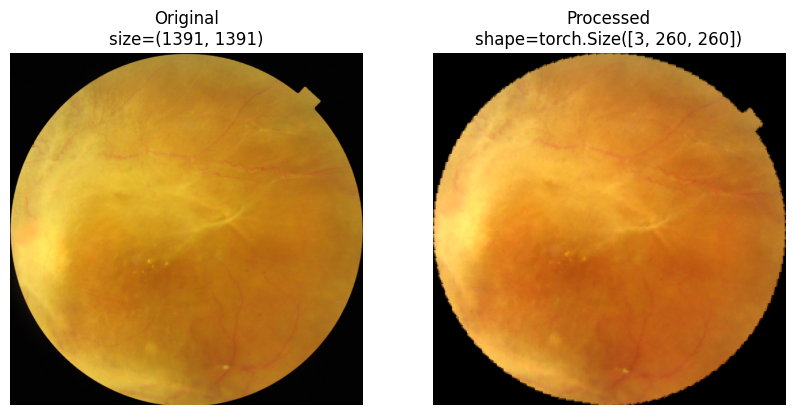

In [ ]:
# --- pick one image ID from your CSV ---
sample_row = train_data.iloc[200]   # first row as example
img_id = str(sample_row["ID"])
img_path = Path("/content/gdrive/MyDrive/GATN/dataset/images/images") / f"{img_id}.png"  # adjust ext/dir

# --- load raw image ---
raw_img = Image.open(img_path).convert("RGB")
print("Original PIL image size:", raw_img.size)  # (width, height)

# --- apply preprocessing (train_tfms or val_tfms) ---
processed_img = train_tfms(raw_img)   # tensor (C,H,W)
print("Processed tensor shape:", processed_img.shape)

# --- unnormalize for plotting (since normalization shifts colors) ---
def unnormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    """Undo normalization so it looks like an image again."""
    tensor = tensor.clone().detach()
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(tensor, 0, 1)

processed_vis = unnormalize(processed_img).permute(1, 2, 0).numpy()  # (H,W,C)

# --- show side by side ---
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(raw_img)
plt.title(f"Original\nsize={raw_img.size}")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(processed_vis)
plt.title(f"Processed\nshape={processed_img.shape}")
plt.axis("off")
plt.show()

## Dataset information

In [ ]:
train_data.drop(columns=["ID"],inplace=True)
val_data.drop(columns=["ID"],inplace=True)
text_labels = [RETINAX_LABEL_EXPANSIONS[label] for label in train_data.columns.to_list()]
print("========================= Labels =============================")
print(f"{train_data.columns.to_list()}, Number of Labels: {len(train_data.columns.to_list())}")
print("========================= Full Text labels =========================")
print(text_labels)
print("========================= Train data size ==============================")
print(f"{train_data.sum()}")
print("========================= Validation data size ============================")
print(f"{val_data.sum()}")

========================= Labels =============================
['DR', 'NORMAL', 'MH', 'ODC', 'TSLN', 'ARMD', 'DN', 'MYA', 'BRVO', 'ODP', 'CRVO', 'CNV', 'RS', 'ODE', 'LS', 'CSR', 'HTR', 'ASR', 'CRS', 'OTHER'], Number of Labels: 20
========================= Full Text labels =========================
['Diabetic Retinopathy', 'Normal retina', 'Media Haze', 'Optic Disc Cupping', 'Retinal Tessellation', 'Age-Related Macular Degeneration', 'Drusen', 'Myopia', 'Branch Retinal Vein Occlusion', 'Optic Disc Pallor', 'Central Retinal Vein Occlusion', 'Choroidal Neovascularization', 'Retinitis', 'Optic Disc Edema', 'Laser Scars', 'Central Serous Retinopathy', 'Hypertensive Retinopathy', 'Arteriosclerotic Retinopathy', 'Chorioretinitis', 'OTHER']
========================= Train data size ==============================
DR        396
NORMAL    395
MH        135
ODC       211
TSLN      125
ARMD      126
DN        130
MYA        71
BRVO       63
ODP        50
CRVO       44
CNV        48
RS         47
OD

# Main

## Configs

In [ ]:
class TrainConfig:
  data_root: str = "/content/gdrive/MyDrive/GATN/dataset"
  train_csv: str = "train_data.csv"
  val_csv: str= "val_data.csv"
  img_dir: str= "images/images"
  exp_name: str = "exp"
  out_root: str = "runs"


  # Model
  model_name: str = "efficientnet_b2"
  freeze_backbone: bool = False


  # Embeddings
  embed_type: str = "pubmed" # "pubmed" | "openai"
  embedding_size = int = 768
  openai_dim: int = 512


  # Adjacency
  matrix_mode: str = "correlation" # "correlation" | "co-occurrence"
  adj_file: str = "Adj_matrix/corr_adj.pkl"
  t1: float = 0.40
  t2: float = 0.20
  A_number: int = 2


  # Train
  img_size: int = 260
  epochs: int = 30
  batch_size: int = 32
  lr: float = 3e-4
  lrp: float = 0.1 # backbone LR multiplier
  lrt: float = 1.0 # transformer LR multiplier
  momentum: float = 0.9
  weight_decay: float = 1e-4
  seed: int = 1337
  threshold: float = 0.5
  num_workers: int = 2
  amp: bool = True
  weight_decay: float = 1e-4
  seed: int = 1337
  threshold: float = 0.5
  num_workers: int = 2
  amp: bool = True

In [ ]:
def train_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    max_grad_norm: Optional[float] = 5.0,
    lambda_consistency: float = 0.1,
    lambda_entropy: float = 0.001,
) -> Tuple[float, float, float, float, float]:
    """
    Returns:
      total_loss, cls_loss, reg_loss, cons_loss, ent_loss (averaged)
    """
    model.train()
    run_total = run_cls = run_reg = run_cons = run_ent = 0.0
    n = 0
    for imgs, targets in tqdm(loader, desc="Train", leave=False):
        x1, x2, targets = _unpack_train_batch(imgs, targets)
        x1, targets = x1.to(device), targets.to(device)
        optimizer.zero_grad(set_to_none=True)

        logits1, reg1, _ = model(x1)
        cls1 = criterion(logits1, targets)

        if x2 is not None:
            x2 = x2.to(device)
            logits2, reg2, _ = model(x2)
            cls2 = criterion(logits2, targets)
            # Consistency on probabilities
            p1 = torch.sigmoid(logits1).detach()  # detach or not? Try without detach to let grads flow through both
            p2 = torch.sigmoid(logits2)
            cons = F.mse_loss(p1, p2)
            # Entropy on the mean prediction (encourages confident agreement)
            pbar = (p1 + p2).clamp(1e-6, 1-1e-6) * 0.5
            ent = -(pbar * torch.log(pbar) + (1 - pbar) * torch.log(1 - pbar)).mean()
            cls_loss = 0.5 * (cls1 + cls2)
            reg_loss = 0.5 * (reg1 + reg2)
            total = cls_loss + reg_loss + lambda_consistency * cons + lambda_entropy * ent
            cons_item, ent_item = cons.item(), ent.item()
        else:
            cls_loss = cls1
            reg_loss = reg1
            total = cls_loss + reg_loss
            cons_item, ent_item = 0.0, 0.0

        total.backward()
        if max_grad_norm is not None:
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        b = x1.size(0)
        run_total += total.item() * b
        run_cls += cls_loss.item() * b
        run_reg += reg_loss.item() * b
        run_cons += cons_item * b
        run_ent  += ent_item  * b
        n += b

    return run_total / n, run_cls / n, run_reg / n, run_cons / n, run_ent / n


@torch.no_grad()
def eval_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> Tuple[float, float, float, np.ndarray, np.ndarray]:
    model.eval()
    run_loss = 0.0
    run_cls = 0.0
    run_reg = 0.0
    n = 0
    all_targets, all_scores = [], []
    for imgs, targets in tqdm(loader, desc="Val", leave=False):
        # Validation uses single view
        if isinstance(imgs, (tuple, list)):
            imgs = imgs[0]
        imgs, targets = imgs.to(device), targets.to(device)
        logits, reg_loss, _ = model(imgs)
        cls_loss = criterion(logits, targets)
        loss = cls_loss + reg_loss
        probs = torch.sigmoid(logits).cpu().numpy()
        all_targets.append(targets.cpu().numpy())
        all_scores.append(probs)
        b = imgs.size(0)
        run_loss += loss.item() * b
        run_cls += cls_loss.item() * b
        run_reg += reg_loss.item() * b
        n += b
    y_true = np.vstack(all_targets)
    y_score = np.vstack(all_scores)
    return run_loss / n, run_cls / n, run_reg / n, y_true, y_score

def lr_lambda(epoch):
    cos = 0.5 * (1 + math.cos(math.pi * epoch / num_epochs))
    return 0.1 + 0.9 * cos  # in [0.1, 1.0]

In [ ]:
# ======================= imports & utils =======================
import os, math, pickle, numpy as np, pandas as pd
from pathlib import Path
from typing import Optional, Sequence, Tuple, Dict
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models as tv_models

try:
    from transformers import AutoTokenizer, AutoModel
    _has_hf = True
except Exception:
    _has_hf = False

from tqdm import tqdm

# -------------- metrics --------------
def _average_precision_ranking(y_true: np.ndarray, y_score: np.ndarray) -> np.ndarray:
    """
    Ranking-based AP (no sklearn). AP_c = mean precision at ranks of positive examples.
    y_true, y_score: shape (N, C)
    Returns: ap per class, shape (C,)
    """
    N, C = y_true.shape
    aps = np.zeros(C, dtype=np.float64)
    for c in range(C):
        t = y_true[:, c].astype(np.int32)
        s = y_score[:, c]
        pos = t.sum()
        if pos == 0:
            aps[c] = 0.0
            continue
        order = np.argsort(-s)  # desc
        t_sorted = t[order]
        # precision at each position
        tp_cum = np.cumsum(t_sorted)
        ranks = np.arange(1, N + 1, dtype=np.float64)
        precision = tp_cum / ranks
        # AP = mean precision at positions where t_sorted == 1
        aps[c] = precision[t_sorted == 1].mean()
    return aps

def _per_label_prf(y_true_bin: np.ndarray, y_pred_bin: np.ndarray, label_names: Sequence[str]) -> pd.DataFrame:
    """
    Per-label Precision/Recall/F1 (+ counts). Returns a DataFrame with columns:
    label, P, R, F1, TP, FP, FN, Support
    """
    eps = 1e-12
    C = y_true_bin.shape[1]
    rows = []
    for c in range(C):
        yt = y_true_bin[:, c].astype(np.int32)
        yp = y_pred_bin[:, c].astype(np.int32)
        TP = int(np.logical_and(yp == 1, yt == 1).sum())
        FP = int(np.logical_and(yp == 1, yt == 0).sum())
        FN = int(np.logical_and(yp == 0, yt == 1).sum())
        support = int(yt.sum())
        P = TP / (TP + FP + eps)
        R = TP / (TP + FN + eps)
        F1 = 2 * P * R / (P + R + eps)
        rows.append((label_names[c], P, R, F1, TP, FP, FN, support))
    df = pd.DataFrame(rows, columns=["label", "P", "R", "F1", "TP", "FP", "FN", "Support"])
    return df

def compute_multi_label_metrics(
    y_true: np.ndarray, y_score: np.ndarray, threshold: float = 0.5
) -> Tuple[Dict[str, float], pd.DataFrame]:
    """
    Returns:
      metrics: dict with mAP, OF1, OP, OR, CF1, CP, CR
      per_label_df: DataFrame with label-wise P/R/F1 (+ counts)
    """
    eps = 1e-12
    y_true = (y_true > 0.5).astype(np.int32)
    y_pred = (y_score >= threshold).astype(np.int32)

    # Overall counts
    TP = int(np.logical_and(y_pred == 1, y_true == 1).sum())
    FP = int(np.logical_and(y_pred == 1, y_true == 0).sum())
    FN = int(np.logical_and(y_pred == 0, y_true == 1).sum())

    OP = TP / (TP + FP + eps)
    OR = TP / (TP + FN + eps)
    OF1 = 2 * OP * OR / (OP + OR + eps)

    # Class-averaged
    df_pl = _per_label_prf(y_true, y_pred, [f"c{i}" for i in range(y_true.shape[1])])
    CP = float(df_pl["P"].mean())
    CR = float(df_pl["R"].mean())
    CF1 = 2 * CP * CR / (CP + CR + eps)

    # mAP (ranking AP per class, then mean)
    ap = _average_precision_ranking(y_true, y_score)
    mAP = float(ap.mean())

    metrics = dict(mAP=mAP, OF1=OF1, OP=OP, OR=OR, CF1=CF1, CP=CP, CR=CR)
    return metrics, df_pl

# ======================= your dataset & transforms (unchanged) =======================
# (Use your already-defined FundusCropToSquare, IMAGENET_MEAN/STD, train_tfms, val_tfms, MultiLabelDataset, etc.)

# ======================= label embeddings =======================
def build_label_embeddings(
    text_labels: Sequence[str],
    embed_name: str = "bert-base-uncased",
    tokenizer_name: Optional[str] = None,
    max_length: int = 16,
    cache_dir: str = "embeddings",
) -> np.ndarray:
    """
    Returns np.ndarray of shape (num_labels, hidden_dim)
    Uses HF model if available; otherwise falls back to a deterministic bag-of-chars embedding.
    """
    os.makedirs(cache_dir, exist_ok=True)
    tokenizer_name = tokenizer_name or embed_name
    cache_path = os.path.join(cache_dir, f"bert_embedding_{embed_name.replace('/', '_')}.pkl")

    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            return pickle.load(f)

    if _has_hf:
        tok = AutoTokenizer.from_pretrained(tokenizer_name)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        mdl = AutoModel.from_pretrained(embed_name).to(device).eval()
        embs = []
        with torch.no_grad():
            for lbl in text_labels:
                toks = tok.encode_plus(lbl, padding="max_length", max_length=max_length,
                                       truncation=True, return_tensors="pt")
                toks = {k: v.to(device) for k, v in toks.items()}
                out = mdl(**toks)
                cls = out.last_hidden_state[:, 0, :].squeeze(0).detach().cpu().numpy()
                embs.append(cls)
        embs = np.vstack(embs)
    else:
        # fallback: simple, deterministic char-hash embedding
        dim = 256
        rng = np.random.RandomState(0)
        table = rng.randn(256, dim).astype(np.float32)
        embs = []
        for lbl in text_labels:
            h = np.zeros((dim,), dtype=np.float32)
            for ch in lbl.encode("utf-8"):
                h += table[ch % 256]
            h /= max(1, len(lbl))
            embs.append(h)
        embs = np.vstack(embs)

    with open(cache_path, "wb") as f:
        pickle.dump(embs, f)
    return embs

# ======================= training / validation loops (FIXED) =======================
def train_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    class_embedding: torch.Tensor,
    max_grad_norm: Optional[float] = 5.0,
) -> float:
    """
    Trains one epoch. Your GATN returns logits only, so we compute standard multi-label loss.
    Returns average loss.
    """
    model.train()
    running = 0.0
    n = 0
    for imgs, targets in tqdm(loader, desc="Train", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(imgs, class_embedding)   # <<<<<< CORRECT CALL
        loss = criterion(logits, targets)
        loss.backward()
        if max_grad_norm is not None:
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        b = imgs.size(0)
        running += loss.item() * b
        n += b
    return running / max(1, n)

@torch.no_grad()
def eval_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    class_embedding: torch.Tensor,
) -> Tuple[float, np.ndarray, np.ndarray]:
    """
    Evaluates one epoch. Returns avg loss, y_true (N,C), y_score (N,C)
    """
    model.eval()
    running = 0.0
    n = 0
    all_true, all_score = [], []
    for imgs, targets in tqdm(loader, desc="Val", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(imgs, class_embedding)    # <<<<<< CORRECT CALL
        loss = criterion(logits, targets)

        probs = torch.sigmoid(logits).cpu().numpy()
        all_true.append(targets.cpu().numpy())
        all_score.append(probs)

        b = imgs.size(0)
        running += loss.item() * b
        n += b

    y_true = np.vstack(all_true)
    y_score = np.vstack(all_score)
    return running / max(1, n), y_true, y_score

# ======================= wire everything up =======================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load labels (you already did this earlier)
label_cols = pd.read_csv("/content/gdrive/MyDrive/GATN/dataset/train_data.csv").columns.drop("ID").tolist()
RETINAX_LABEL_EXPANSIONS = {
    "DR": "Diabetic Retinopathy",
    "NORMAL": "Normal retina",
    "MH": "Media Haze",
    "ODC": "Optic Disc Cupping",
    "TSLN": "Retinal Tessellation",
    "ARMD": "Age-Related Macular Degeneration",
    "DN": "Drusen",
    "MYA": "Myopia",
    "BRVO": "Branch Retinal Vein Occlusion",
    "ODP": "Optic Disc Pallor",
    "CRVO": "Central Retinal Vein Occlusion",
    "CNV": "Choroidal Neovascularization",
    "RS": "Retinitis",
    "ODE": "Optic Disc Edema",
    "LS": "Laser Scars",
    "CSR": "Central Serous Retinopathy",
    "HTR": "Hypertensive Retinopathy",
    "ASR": "Arteriosclerotic Retinopathy",
    "CRS": "Chorioretinitis",
    "OTHER": "OTHER",
}
text_labels = [RETINAX_LABEL_EXPANSIONS[k] for k in label_cols]

# Build/Load label embeddings (shape must be (num_classes, TrainConfig.embedding_size))
np_emb = build_label_embeddings(
    text_labels,
    embed_name=getattr(TrainConfig, "embed_name", "bert-base-uncased"),
    tokenizer_name=getattr(TrainConfig, "tokenizer_name", None),
    max_length=getattr(TrainConfig, "embed_max_length", 16),
    cache_dir="embeddings",
)
if np_emb.shape[0] != len(label_cols):
    raise ValueError(f"Embedding rows {np_emb.shape[0]} != num_labels {len(label_cols)}")
if np_emb.shape[1] != TrainConfig.embedding_size:
    raise ValueError(
        f"Embedding dim {np_emb.shape[1]} != TrainConfig.embedding_size {TrainConfig.embedding_size}. "
        f"Set TrainConfig.embedding_size={np_emb.shape[1]} or change the embedding model."
    )
emb_tensor = torch.tensor(np_emb, dtype=torch.float32, device=device)  # (C, D)

# Datasets / loaders (yours are fine)
train_dataset = MultiLabelDataset(
    "/content/gdrive/MyDrive/GATN/dataset/train_data.csv",
    img_dir="/content/gdrive/MyDrive/GATN/dataset/images/images",
    label_cols=label_cols,
    transform=train_tfms,
)
val_dataset = MultiLabelDataset(
    "/content/gdrive/MyDrive/GATN/dataset/val_data.csv",
    img_dir="/content/gdrive/MyDrive/GATN/dataset/images/images",
    label_cols=label_cols,
    transform=val_tfms,
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# Model
model = GATN(
    model_name=TrainConfig.model_name,
    num_classes=len(label_cols),
    t1=TrainConfig.t1,
    t2=TrainConfig.t2,
    A_number=TrainConfig.A_number,
    adj_file=TrainConfig.adj_file,
    matrix_mode=TrainConfig.matrix_mode,
    embedding_size=TrainConfig.embedding_size,
).to(device)

# Loss & optimizer & scheduler
criterion = nn.MultiLabelSoftMarginLoss()
optimizer = torch.optim.SGD(
    model.get_config_optim(TrainConfig.lr, TrainConfig.lrp, TrainConfig.lrt),
    lr=TrainConfig.lr,
    momentum=TrainConfig.momentum,
    weight_decay=TrainConfig.weight_decay,
)
num_epochs = 40
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda ep: 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * ep / num_epochs)))

# ======================= training loop (CLEAN) =======================
best_of1 = -1.0
best_path = Path("./best_gatn_by_OF1.pth")
per_label_dir = Path("./per_label_prf")
per_label_dir.mkdir(parents=True, exist_ok=True)

for epoch in range(1, num_epochs + 1):
    train_loss = train_epoch(model, train_loader, optimizer, criterion, device, emb_tensor, max_grad_norm=5.0)
    val_loss, y_true, y_score = eval_epoch(model, val_loader, criterion, device, emb_tensor)

    # metrics @ 0.5
    metrics, df_pl = compute_multi_label_metrics(y_true, y_score, threshold=0.5)
    # replace auto label names with your actual label names
    df_pl["label"] = label_cols
    df_pl = df_pl[["label", "P", "R", "F1", "TP", "FP", "FN", "Support"]].sort_values("F1", ascending=False)

    # log
    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"TrainLoss {train_loss:.4f} | ValLoss {val_loss:.4f} || "
        f"mAP {metrics['mAP']:.4f} | OF1 {metrics['OF1']:.4f} "
        f"| OP {metrics['OP']:.4f} OR {metrics['OR']:.4f} "
        f"| CF1 {metrics['CF1']:.4f} | CP {metrics['CP']:.4f} CR {metrics['CR']:.4f}"
    )

    # save per-label table
    df_pl.to_csv(per_label_dir / f"val_prf_epoch{epoch:02d}_thr0.5.csv", index=False)

    # checkpoint by OF1
    if metrics["OF1"] > best_of1:
        best_of1 = metrics["OF1"]
        torch.save({
            "model": model.state_dict(),
            "label_cols": label_cols,
            "metrics@0.5": metrics,
        }, best_path)
        print(f"  ↳ New best OF1={best_of1:.4f}. Saved to {best_path}")

    scheduler.step()

print("Training complete.")
print(f"Best checkpoint by OF1: {best_path} (OF1={best_of1:.4f})")


Epoch 01/40 | TrainLoss 0.6934 | ValLoss 0.6871 || mAP 0.0722 | OF1 0.1225 | OP 0.0709 OR 0.4506 | CF1 0.0972 | CP 0.0558 CR 0.3778
  ↳ New best OF1=0.1225. Saved to best_gatn_by_OF1.pth


Epoch 02/40 | TrainLoss 0.6831 | ValLoss 0.6774 || mAP 0.0753 | OF1 0.1325 | OP 0.0776 OR 0.4524 | CF1 0.0802 | CP 0.0453 CR 0.3491
  ↳ New best OF1=0.1325. Saved to best_gatn_by_OF1.pth


Epoch 03/40 | TrainLoss 0.6709 | ValLoss 0.6623 || mAP 0.0762 | OF1 0.1396 | OP 0.0824 OR 0.4560 | CF1 0.0746 | CP 0.0418 CR 0.3452
  ↳ New best OF1=0.1396. Saved to best_gatn_by_OF1.pth


Epoch 04/40 | TrainLoss 0.6497 | ValLoss 0.6341 || mAP 0.0734 | OF1 0.1431 | OP 0.0857 OR 0.4327 | CF1 0.0532 | CP 0.0292 CR 0.3017
  ↳ New best OF1=0.1431. Saved to best_gatn_by_OF1.pth


Epoch 05/40 | TrainLoss 0.6084 | ValLoss 0.5818 || mAP 0.0742 | OF1 0.1497 | OP 0.0974 OR 0.3232 | CF1 0.0427 | CP 0.0238 CR 0.2094
  ↳ New best OF1=0.1497. Saved to best_gatn_by_OF1.pth


Epoch 06/40 | TrainLoss 0.5332 | ValLoss 0.4897 || mAP 0.0743 | OF1 0.1492 | OP 0.0980 OR 0.3124 | CF1 0.0357 | CP 0.0196 CR 0.2000


... (6 outputs left out)

Epoch 13/40 | TrainLoss 0.2216 | ValLoss 0.2256 || mAP 0.0804 | OF1 0.0000 | OP 0.0000 OR 0.0000 | CF1 0.0000 | CP 0.0000 CR 0.0000


Epoch 14/40 | TrainLoss 0.2204 | ValLoss 0.2241 || mAP 0.0820 | OF1 0.0000 | OP 0.0000 OR 0.0000 | CF1 0.0000 | CP 0.0000 CR 0.0000


Epoch 15/40 | TrainLoss 0.2184 | ValLoss 0.2225 || mAP 0.0809 | OF1 0.0000 | OP 0.0000 OR 0.0000 | CF1 0.0000 | CP 0.0000 CR 0.0000


KeyboardInterrupt: 

In [ ]:
# train_gatn.py
# Clean GATN training (no class balancing, no threshold tuning)
# Metrics: OF1 OP OR CF1 CP CR + per-label F1/R/P (saved each epoch)

from __future__ import annotations
import os, math, pickle, argparse, random
from dataclasses import dataclass
from pathlib import Path
from typing import Optional, Sequence, Tuple, Dict, List

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models as tv_models
from tqdm import tqdm

# Optional: timm & HuggingFace (fall back cleanly if unavailable)
try:
    import timm
    _has_timm = True
except Exception:
    _has_timm = False

try:
    from transformers import AutoTokenizer, AutoModel
    _has_hf = True
except Exception:
    _has_hf = False

# ---------------------- PATHS (edit these or use CLI) ----------------------
DATA_ROOT = Path("/content/gdrive/MyDrive/GATN/dataset")
TRAIN_CSV = DATA_ROOT / "train_data.csv"
VAL_CSV   = DATA_ROOT / "val_data.csv"
IMG_DIR   = DATA_ROOT / "images" / "images"

RUN_DIR   = Path("./runs_gatn")
RUN_DIR.mkdir(parents=True, exist_ok=True)
# ---------------------------------------------------------------------------

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(42)
torch.backends.cudnn.benchmark = True

# ---------------------- Config --------------------------------------------
@dataclass
class TrainConfig:
    model_name: str = "efficientnet_b2"     # any timm or torchvision backbone
    pool: str = "max"                # "avg"|"max"|"gem" (timm); torchvision uses its default avg
    img_size: int = 260              # change freely for your backbone
    batch_size: int = 32
    num_workers: int = 2
    lr: float = 1e-2
    lrp: float = 0.1                 # backbone LR multiplier
    lrt: float = 1.0                 # transformer LR multiplier
    momentum: float = 0.9
    weight_decay: float = 1e-4
    num_epochs: int = 40

    # label embedding model (HF). If HF unavailable, falls back to char-hash
    embed_name: str = "bert-base-uncased"
    embed_max_length: int = 300

    # adjacency from label embeddings
    tau: float = 0.20                # threshold τ
    alpha: float = 0.25              # column reweighting α

CFG = TrainConfig()

# ---------------------- Backbone loaders ----------------------------------
class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps
    def forward(self, x):
        x = x.clamp(min=self.eps).pow(self.p)
        x = torch.mean(x, dim=(-2, -1), keepdim=True)
        return x.pow(1.0 / self.p)

def load_backbone(model_name: str, pretrained: bool = True, pool: str = "max", freeze: bool = False):
    name = (model_name or "").lower()

    # timm path (supports global_pool)
    if _has_timm:
        if pool in {"avg","max","avgmax","cat"}:
            m = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool=pool)
            feat_dim = getattr(m, "num_features", None)
            if freeze:
                for p in m.parameters(): p.requires_grad = False
            return m, feat_dim
        if pool == "gem":
            base = timm.create_model(name, pretrained=pretrained, num_classes=0, global_pool="")
            feat_dim = getattr(base, "num_features", None)
            gem = GeM()
            class TimmGeM(nn.Module):
                def __init__(self, backbone, pool): super().__init__(); self.backbone=backbone; self.pool=pool
                def forward(self, x):
                    f = self.backbone.forward_features(x)
                    if f.dim()==4: f = self.pool(f).flatten(1)
                    elif f.dim()==3: f = f.mean(1)
                    return f
            m = TimmGeM(base, gem)
            if freeze:
                for p in m.parameters(): p.requires_grad = False
            return m, feat_dim

    # torchvision fallback (uses avgpool internally)
    if name in {"resnet18","resnet34","resnet50","resnet101","resnet152"}:
        wmap = {
            "resnet18":  tv_models.ResNet18_Weights,
            "resnet34":  tv_models.ResNet34_Weights,
            "resnet50":  tv_models.ResNet50_Weights,
            "resnet101": tv_models.ResNet101_Weights,
            "resnet152": tv_models.ResNet152_Weights,
        }
        weights = getattr(wmap[name], "IMAGENET1K_V1")
        m = getattr(tv_models, name)(weights=weights)
        feat_dim = m.fc.in_features
        m.fc = nn.Identity()  # pooled features after avgpool
        if pool == "gem":
            m.avgpool = GeM()
        if freeze:
            for p in m.parameters(): p.requires_grad = False
        return m, feat_dim

    raise ValueError(f"Unknown backbone: {model_name}")

# ---------------------- Label embeddings ----------------------------------
def build_label_embeddings(
    text_labels: Sequence[str],
    embed_name: str,
    max_length: int,
    cache_dir: Path = Path("embeddings"),
) -> np.ndarray:
    """
    Returns np.ndarray (C, D). Cached by model name. If HF not available, uses
    deterministic char-hash embedding (D=256).
    """
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_path = cache_dir / f"labels_{embed_name.replace('/','_')}.pkl"
    if cache_path.exists():
        with open(cache_path, "rb") as f:
            return pickle.load(f)

    if _has_hf:
        tok = AutoTokenizer.from_pretrained(embed_name)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        mdl = AutoModel.from_pretrained(embed_name).to(device).eval()
        out = []
        with torch.no_grad():
            for s in text_labels:
                t = tok.encode_plus(s, padding="max_length", max_length=max_length,
                                   truncation=True, return_tensors="pt")
                t = {k: v.to(device) for k, v in t.items()}
                cls = mdl(**t).last_hidden_state[:,0,:].squeeze(0).detach().cpu().numpy()
                out.append(cls)
        embs = np.vstack(out)
    else:
        # fallback: char-hash (deterministic)
        dim = 256
        rng = np.random.RandomState(0)
        table = rng.randn(256, dim).astype(np.float32)
        out = []
        for s in text_labels:
            v = np.zeros((dim,), dtype=np.float32)
            b = s.encode("utf-8")
            for ch in b: v += table[ch % 256]
            v /= max(1, len(b))
            out.append(v)
        embs = np.vstack(out)

    with open(cache_path, "wb") as f:
        pickle.dump(embs, f)
    return embs

# ---------------------- Adjacency from text embeddings --------------------
def gen_A_from_label_embeddings(emb: np.ndarray, tau: float = 0.2, alpha: float = 0.25) -> np.ndarray:
    """
    E -> cosine similarity -> single τ threshold -> column reweight α.
    """
    E = torch.tensor(emb, dtype=torch.float32)
    E = F.normalize(E, dim=1)
    S = (E @ E.T).cpu().numpy()
    np.fill_diagonal(S, 1.0)
    A = (S >= tau).astype(np.float32)
    A = alpha * A / (A.sum(0, keepdims=True) + 1e-6)
    return A

def gen_adj(A: torch.Tensor) -> torch.Tensor:
    D = torch.pow(A.sum(1).float().clamp_min(1e-6), -0.5)
    D = torch.diag(D)
    return D @ A @ D

# ---------------------- Model parts ---------------------------------------
class SelfAttention(nn.Module):
    def __init__(self, embed_size: int, heads: int):
        super().__init__()
        assert embed_size % heads == 0, "embed_size must be divisible by heads"
        self.heads = heads
        self.embed_size = embed_size
        self.head_dim = embed_size // heads
        self.q_proj = nn.Linear(self.head_dim, self.head_dim, bias=False)
        self.k_proj = nn.Linear(self.head_dim, self.head_dim, bias=False)
        self.v_proj = nn.Linear(self.head_dim, self.head_dim, bias=False)
        self.fc_out = nn.Linear(embed_size, embed_size)

    def forward(self, values, keys, query, mask=None):
        N = query.shape[0]
        value_len, key_len, query_len = values.shape[1], keys.shape[1], query.shape[1]
        values = values.reshape(N, value_len, self.heads, self.head_dim)
        keys   = keys.reshape(N, key_len,  self.heads, self.head_dim)
        query  = query.reshape(N, query_len, self.heads, self.head_dim)
        q = self.q_proj(query); k = self.k_proj(keys); v = self.v_proj(values)
        energy = torch.einsum("nqhd,nkhd->nhqk", q, k)
        if mask is not None: energy = energy.masked_fill(mask == 0, float("-1e20"))
        attn = torch.softmax(energy / (self.head_dim**0.5), dim=-1)
        out = torch.einsum("nhqk,nkhd->nqhd", attn, v)
        out = out.reshape(N, query_len, self.heads * self.head_dim)
        return self.fc_out(out)

class AttentionBlock(nn.Module):
    def __init__(self, embed_size: int, heads: int):
        super().__init__()
        self.embed_size = embed_size
        self.norm = nn.LayerNorm(embed_size, eps=1e-6)
        self.attn1 = SelfAttention(embed_size, heads)
        self.attn2 = SelfAttention(embed_size, heads)
        self.attn3 = SelfAttention(embed_size, heads)
        self.attn4 = SelfAttention(embed_size, heads)

    def forward(self, x, mask=None):
        if x.dim() == 2: x = x.unsqueeze(0)
        B, L, D = x.shape
        if D != self.embed_size:
            raise ValueError(f"x hidden size {D} != embed_size {self.embed_size}")
        x1 = self.attn1(self.norm(x), self.norm(x), self.norm(x), mask)
        x2 = self.attn2(self.norm(x), self.norm(x), self.norm(x), mask)
        y1 = self.attn3(self.norm(x), self.norm(x), self.norm(x), mask)
        y2 = self.attn4(self.norm(x), self.norm(x), self.norm(x), mask)
        x1 = x1 + y1; x2 = x2 + y2
        return torch.bmm(x1, x2.transpose(1, 2)).squeeze(0)  # (N,N)

class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=False):
        super().__init__()
        self.weight = nn.Parameter(torch.FloatTensor(in_features, out_features))
        if bias: self.bias = nn.Parameter(torch.FloatTensor(1, 1, out_features))
        else:    self.register_parameter("bias", None)
        self.reset_parameters()
    def reset_parameters(self):
        stdv = 1.0 / math.sqrt(self.weight.size(1))
        nn.init.uniform_(self.weight, -stdv, stdv)
        if self.bias is not None: nn.init.uniform_(self.bias, -stdv, stdv)
    def forward(self, x, adj):
        out = adj @ (x @ self.weight)
        return out + self.bias if self.bias is not None else out

class GATN(nn.Module):
    def __init__(self, model_name: str, num_classes: int, embedding_size: int, pool: str = "max"):
        super().__init__()
        self.num_classes = num_classes
        self.embedding_size = embedding_size
        self.backbone, feat_dim = load_backbone(model_name, pretrained=True, pool=pool, freeze=False)
        self.feat_proj = nn.Linear(feat_dim, 1024)
        self.gc1 = GraphConvolution(embedding_size, 512)
        self.gc2 = GraphConvolution(512, 1024)
        self.relu = nn.ReLU(inplace=True)
        self.transformerblock = AttentionBlock(num_classes, heads=2)
        self.linear_A = nn.Linear(num_classes, num_classes)
        self.register_buffer("A_base", torch.zeros(num_classes, num_classes), persistent=False)
    def set_base_adj(self, A_base: np.ndarray | torch.Tensor):
        if isinstance(A_base, np.ndarray): A_base = torch.from_numpy(A_base).float()
        assert A_base.shape == (self.num_classes, self.num_classes)
        self.A_base = A_base
    def forward(self, image: torch.Tensor, label_embeddings: torch.Tensor) -> torch.Tensor:
        # --- visual ---
        feat = self.backbone(image)              # (B, F)
        feat = self.feat_proj(feat)              # (B, 1024)

        # --- adjacency via attention ---
        A0   = self.A_base.to(image.device, dtype=feat.dtype)  # (N, N)
        Araw = self.transformerblock(A0.unsqueeze(0))          # (N, N)

        # ✅ NEW: clamp negatives to zero so GCN sees a non-negative graph
        Araw = torch.relu(Araw)

        # add self-loops and normalize
        I = torch.eye(self.num_classes, device=Araw.device, dtype=Araw.dtype)
        A = gen_adj(Araw + I)                    # (N, N)

        # --- GCN over label embeddings ---
        emb = label_embeddings.to(feat.device, dtype=feat.dtype)  # (N, D)
        x   = self.gc1(emb, A)
        x   = self.relu(x)
        x   = self.gc2(x, A).t()                 # (1024, N)

        # --- fuse ---
        out = self.linear_A(feat @ x)            # (B, N)
        return out
    def get_config_optim(self, lr, lrp, lrt):
        return [
            {"params": self.backbone.parameters(),       "lr": lr * lrp},
            {"params": self.transformerblock.parameters(),"lr": lr * lrt},
            {"params": self.gc1.parameters(),            "lr": lr},
            {"params": self.gc2.parameters(),            "lr": lr},
            {"params": self.feat_proj.parameters(),      "lr": lr},
            {"params": self.linear_A.parameters(),       "lr": lr},
        ]

# ---------------------- Data ----------------------------------------------
class FundusCropToSquare:
    def __call__(self, img: Image.Image) -> Image.Image:
        if img.mode != "RGB": img = img.convert("RGB")
        gray = ImageOps.grayscale(img); npg = np.array(gray)
        mask = npg > 5
        if not mask.any(): return img
        ys, xs = np.where(mask)
        x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
        img = img.crop((x0, y0, x1+1, y1+1))
        w, h = img.size; side = max(w,h)
        pad_w, pad_h = side - w, side - h
        pad = (pad_w//2, pad_h//2, pad_w - pad_w//2, pad_h - pad_h//2)
        return ImageOps.expand(img, border=pad, fill=0)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

def make_transforms(img_size: int):
    train_tfms = transforms.Compose([
        FundusCropToSquare(),
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15, expand=False),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])
    val_tfms = transforms.Compose([
        FundusCropToSquare(),
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])
    return train_tfms, val_tfms

class MultiLabelDataset(Dataset):
    def __init__(self, csv_path: Path|str, img_dir: Path|str, label_cols: Sequence[str],
                 transform: Optional[transforms.Compose]=None,
                 img_extensions: Optional[Sequence[str]]=None):
        self.df = pd.read_csv(csv_path)
        self.img_dir = Path(img_dir)
        self.label_cols = list(label_cols)
        self.transform = transform
        self.img_exts = list(img_extensions) if img_extensions else [".png",".jpg",".jpeg",".bmp",".tif",".tiff"]
    def __len__(self): return len(self.df)
    def _find_image(self, img_id: str) -> Path:
        for ext in self.img_exts:
            p = self.img_dir / f"{img_id}{ext}"
            if p.exists(): return p
        raise FileNotFoundError(f"No image for ID '{img_id}' in {self.img_dir}")
    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        img_id = str(row["ID"])
        img_path = self._find_image(img_id)
        with Image.open(img_path) as im: img = im.convert("RGB")
        if self.transform: img = self.transform(img)
        labels = torch.tensor(row[self.label_cols].to_numpy(dtype=float), dtype=torch.float32)
        return img, labels

# ---------------------- Metrics (fixed threshold=0.5) ---------------------
def _average_precision_ranking(y_true: np.ndarray, y_score: np.ndarray) -> np.ndarray:
    N, C = y_true.shape
    aps = np.zeros(C, dtype=np.float64)
    for c in range(C):
        t = y_true[:, c].astype(np.int32); s = y_score[:, c]
        pos = t.sum()
        if pos == 0: aps[c] = 0.0; continue
        order = np.argsort(-s); t_sorted = t[order]
        tp_cum = np.cumsum(t_sorted)
        ranks = np.arange(1, N + 1, dtype=np.float64)
        precision = tp_cum / ranks
        aps[c] = precision[t_sorted == 1].mean() if (t_sorted == 1).any() else 0.0
    return aps

def _per_label_prf(y_true_bin: np.ndarray, y_pred_bin: np.ndarray, label_names: Sequence[str]) -> pd.DataFrame:
    eps = 1e-12
    rows = []
    C = y_true_bin.shape[1]
    for c in range(C):
        yt = y_true_bin[:, c].astype(np.int32)
        yp = y_pred_bin[:, c].astype(np.int32)
        TP = int(np.logical_and(yp == 1, yt == 1).sum())
        FP = int(np.logical_and(yp == 1, yt == 0).sum())
        FN = int(np.logical_and(yp == 0, yt == 1).sum())
        P = TP / (TP + FP + eps)
        R = TP / (TP + FN + eps)
        F1 = 2 * P * R / (P + R + eps)
        rows.append((label_names[c], F1, R, P, TP, FP, FN, int(yt.sum())))
    return pd.DataFrame(rows, columns=["label","F1","R","P","TP","FP","FN","Support"])

def compute_multi_label_metrics(y_true: np.ndarray, y_score: np.ndarray, label_names: Sequence[str],
                                threshold: float = 0.5) -> Tuple[Dict[str,float], pd.DataFrame]:
    eps = 1e-12
    y_true = (y_true > 0.5).astype(np.int32)
    y_pred = (y_score >= threshold).astype(np.int32)

    TP = int(np.logical_and(y_pred == 1, y_true == 1).sum())
    FP = int(np.logical_and(y_pred == 1, y_true == 0).sum())
    FN = int(np.logical_and(y_pred == 0, y_true == 1).sum())

    OP = TP / (TP + FP + eps)
    OR = TP / (TP + FN + eps)
    OF1 = 2 * OP * OR / (OP + OR + eps)

    per_label = _per_label_prf(y_true, y_pred, label_names)
    CP = float(per_label["P"].mean())
    CR = float(per_label["R"].mean())
    CF1 = 2 * CP * CR / (CP + CR + eps)

    mAP = float(_average_precision_ranking(y_true, y_score).mean())

    metrics = dict(mAP=mAP, OF1=OF1, OP=OP, OR=OR, CF1=CF1, CP=CP, CR=CR)
    return metrics, per_label

# ---------------------- Train / Eval loops --------------------------------
def train_epoch(model, loader, optimizer, criterion, device, class_embedding: torch.Tensor,
                max_grad_norm: Optional[float]=5.0) -> float:
    model.train()
    running, n = 0.0, 0
    for imgs, targets in tqdm(loader, desc="Train", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(imgs, class_embedding)
        loss = criterion(logits, targets)
        loss.backward()
        if max_grad_norm is not None:
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()
        b = imgs.size(0); running += loss.item() * b; n += b
    return running / max(1,n)

@torch.no_grad()
def eval_epoch(model, loader, criterion, device, class_embedding: torch.Tensor) -> Tuple[float, np.ndarray, np.ndarray]:
    model.eval()
    running, n = 0.0, 0
    all_true, all_score = [], []
    for imgs, targets in tqdm(loader, desc="Val", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        logits = model(imgs, class_embedding)
        loss = criterion(logits, targets)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_true.append(targets.cpu().numpy()); all_score.append(probs)
        b = imgs.size(0); running += loss.item() * b; n += b
    y_true = np.vstack(all_true); y_score = np.vstack(all_score)
    return running / max(1,n), y_true, y_score

# ---------------------- Main ----------------------------------------------
def main():
    # parser = argparse.ArgumentParser()
    # parser.add_argument("--model_name", type=str, default=CFG.model_name)
    # parser.add_argument("--pool", type=str, default=CFG.pool, choices=["avg","max","gem"])
    # parser.add_argument("--img_size", type=int, default=CFG.img_size)
    # parser.add_argument("--batch_size", type=int, default=CFG.batch_size)
    # parser.add_argument("--epochs", type=int, default=CFG.num_epochs)
    # args = parser.parse_args()

    # # hydrate config from CLI
    # CFG.model_name = args.model_name
    # CFG.pool = args.pool
    # CFG.img_size = args.img_size
    # CFG.batch_size = args.batch_size
    # CFG.num_epochs = args.epochs

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # labels
    label_cols = pd.read_csv(TRAIN_CSV).columns.drop("ID").tolist()
    RETINAX_LABEL_EXPANSIONS = {
        "DR":"Diabetic Retinopathy","NORMAL":"Normal retina","MH":"Media Haze","ODC":"Optic Disc Cupping",
        "TSLN":"Retinal Tessellation","ARMD":"Age-Related Macular Degeneration","DN":"Drusen","MYA":"Myopia",
        "BRVO":"Branch Retinal Vein Occlusion","ODP":"Optic Disc Pallor","CRVO":"Central Retinal Vein Occlusion",
        "CNV":"Choroidal Neovascularization","RS":"Retinitis","ODE":"Optic Disc Edema","LS":"Laser Scars",
        "CSR":"Central Serous Retinopathy","HTR":"Hypertensive Retinopathy","ASR":"Arteriosclerotic Retinopathy",
        "CRS":"Chorioretinitis","OTHER":"OTHER",
    }
    text_labels = [RETINAX_LABEL_EXPANSIONS.get(k, k) for k in label_cols]

    # label embeddings & base adjacency
    np_emb = build_label_embeddings(text_labels, embed_name=CFG.embed_name, max_length=CFG.embed_max_length)
    C, D = np_emb.shape
    emb_tensor = torch.tensor(np_emb, dtype=torch.float32, device=device)
    A_base = gen_A_from_label_embeddings(np_emb, tau=CFG.tau, alpha=CFG.alpha)

    # datasets / loaders
    train_tfms, val_tfms = make_transforms(CFG.img_size)
    train_ds = MultiLabelDataset(TRAIN_CSV, IMG_DIR, label_cols, transform=train_tfms)
    val_ds   = MultiLabelDataset(VAL_CSV,   IMG_DIR, label_cols, transform=val_tfms)
    train_loader = DataLoader(train_ds, batch_size=CFG.batch_size, shuffle=True,
                              num_workers=CFG.num_workers, pin_memory=True, drop_last=True)
    val_loader   = DataLoader(val_ds,   batch_size=CFG.batch_size, shuffle=False,
                              num_workers=CFG.num_workers, pin_memory=True)

    # model
    model = GATN(model_name=CFG.model_name, num_classes=C, embedding_size=D, pool=CFG.pool).to(device)
    model.set_base_adj(A_base)

    # plain BCE-with-logits (no class balancing)
    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.SGD(model.get_config_optim(CFG.lr, CFG.lrp, CFG.lrt),
                                lr=CFG.lr, momentum=CFG.momentum, weight_decay=CFG.weight_decay)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lr_lambda=lambda ep: 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * ep / CFG.num_epochs))
    )

    best_of1 = -1.0
    ckpt_path = RUN_DIR / "best_gatn_by_OF1.pth"
    per_label_dir = RUN_DIR / "per_label_prf"
    per_label_dir.mkdir(exist_ok=True, parents=True)

    for epoch in range(1, CFG.num_epochs + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion, device, emb_tensor, max_grad_norm=5.0)
        val_loss, y_true, y_score = eval_epoch(model, val_loader, criterion, device, emb_tensor)

        # metrics @ fixed 0.5
        metrics, df_pl = compute_multi_label_metrics(y_true, y_score, label_cols, threshold=0.5)

        print(
            f"Epoch {epoch:02d}/{CFG.num_epochs} | "
            f"TrainLoss {train_loss:.4f} | ValLoss {val_loss:.4f} || "
            f"mAP {metrics['mAP']:.4f} | OF1 {metrics['OF1']:.4f} "
            f"| OP {metrics['OP']:.4f} OR {metrics['OR']:.4f} "
            f"| CF1 {metrics['CF1']:.4f} | CP {metrics['CP']:.4f} CR {metrics['CR']:.4f}"
        )

        # save per-label table (columns exactly: label, F1, R, P, TP, FP, FN, Support)
        df_pl.sort_values("F1", ascending=False).to_csv(per_label_dir / f"val_prf_epoch{epoch:02d}.csv", index=False)

        if metrics["OF1"] > best_of1:
            best_of1 = metrics["OF1"]
            torch.save(
                {
                    "model": model.state_dict(),
                    "label_cols": label_cols,
                    "text_labels": text_labels,
                    "embed_name": CFG.embed_name,
                    "embedding_dim": D,
                    "A_base_params": {"tau": CFG.tau, "alpha": CFG.alpha},
                    "metrics@0.5": metrics,
                },
                ckpt_path,
            )
            print(f"  ↳ New best OF1={best_of1:.4f}. Saved to {ckpt_path}")

        scheduler.step()

    print("Training complete.")
    print(f"Best checkpoint by OF1@0.5: {ckpt_path} (OF1={best_of1:.4f})")

if __name__ == "__main__":
    main()


Epoch 01/40 | TrainLoss 0.6575 | ValLoss 0.2020 || mAP 0.1401 | OF1 0.0177 | OP 0.6250 OR 0.0090 | CF1 0.0048 | CP 0.0417 CR 0.0026
  ↳ New best OF1=0.0177. Saved to runs_gatn/best_gatn_by_OF1.pth


Epoch 02/40 | TrainLoss 0.2001 | ValLoss 0.1892 || mAP 0.1992 | OF1 0.1880 | OP 0.6630 OR 0.1095 | CF1 0.0535 | CP 0.1218 CR 0.0342
  ↳ New best OF1=0.1880. Saved to runs_gatn/best_gatn_by_OF1.pth


Epoch 03/40 | TrainLoss 0.1871 | ValLoss 0.1885 || mAP 0.2113 | OF1 0.1914 | OP 0.6813 OR 0.1113 | CF1 0.0661 | CP 0.1677 CR 0.0411
  ↳ New best OF1=0.1914. Saved to runs_gatn/best_gatn_by_OF1.pth


Epoch 04/40 | TrainLoss 0.1787 | ValLoss 0.1829 || mAP 0.2304 | OF1 0.3065 | OP 0.5800 OR 0.2083 | CF1 0.1197 | CP 0.1645 CR 0.0941
  ↳ New best OF1=0.3065. Saved to runs_gatn/best_gatn_by_OF1.pth


KeyboardInterrupt: 